# TinyBERT Matryoshka Representation Learning for Indic Languages

This notebook tests whether MRL improves Indic-language sentence representations. It trains a 768-dimensional TinyBERT encoder on 20,240 unlabeled Indic sentences using two dropout views of each sentence, a symmetric InfoNCE objective, and nested dimensions `[16, 32, 64, 128, 256, 512, 768]`. It then compares the fine-tuned encoder with the original frozen checkpoint using logistic-regression probes on five language-specific IndicSentiment splits.


In [18]:
!pip -q install -U transformers seaborn tqdm

In [ ]:
import os
import gc
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel, get_scheduler


MODEL_NAME = "huawei-noah/TinyBERT_General_6L_768D"
DIMENSIONS = [16, 32, 64, 128, 256, 512, 768]
SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 32
GRAD_ACCUM_STEPS = 1
EPOCHS = 5
LEARNING_RATE = 2e-5
WARMUP_RATIO = 0.1
TEMPERATURE = 0.05
NUM_WORKERS = 2

def first_existing(*paths):
    for path in paths:
        path = Path(path)
        if path.exists():
            return path
    return None

DATA_ROOT = first_existing(
    "/kaggle/input/datasets/saharshburra/indic-data/data",
    Path.cwd(),
)
TRAIN_CSV = first_existing(
    DATA_ROOT / "data/indic_mrl/indic_mrl_train.csv",
    DATA_ROOT / "indic_mrl/indic_mrl_train.csv",
)
INDIC_DIR = first_existing(
    DATA_ROOT / "data/indic",
    DATA_ROOT / "indic",
    DATA_ROOT,
)
OUTPUT_DIR = Path("tinybert_indic_mrl_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LANGUAGES = ["hi", "bn", "gu", "ta", "te"]

if TRAIN_CSV is None or any(not (INDIC_DIR / f"{lang}_{split}.csv").exists() for lang in LANGUAGES for split in ["train", "test"]):
    raise FileNotFoundError(
        "Could not find the uploaded CSV files. Set DATA_ROOT, TRAIN_CSV, and INDIC_DIR "
        "to the mounted Kaggle dataset paths, then rerun this cell."
    )

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print(f"Training data: {TRAIN_CSV}")
print(f"Indic evaluation data: {INDIC_DIR}")

Device: cuda
GPU: Tesla T4
VRAM: 14.6 GB
Training data: /kaggle/input/datasets/saharshburra/indic-data/data/indic_mrl/indic_mrl_train.csv
Indic evaluation data: /kaggle/input/datasets/saharshburra/indic-data/data/indic


## Load data and TinyBERT

The training objective uses two independently tokenized and dropout-perturbed views of the same sentence as the positive pair. Mean pooling averages the non-padding token representations and is used consistently for both training and evaluation. The MRL loss applies symmetric InfoNCE to every listed prefix dimension.

In [20]:
train_df = pd.read_csv(TRAIN_CSV).dropna(subset=["text"]).reset_index(drop=True)
if "language" in train_df:
    display(train_df["language"].value_counts().rename("count").to_frame())
print(f"Training examples: {len(train_df):,}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.add_special_tokens({"pad_token": "[PAD]"})
model = AutoModel.from_pretrained(MODEL_NAME)
if len(tokenizer) != model.get_input_embeddings().num_embeddings:
    model.resize_token_embeddings(len(tokenizer))
HIDDEN_SIZE = int(model.config.hidden_size)
if max(DIMENSIONS) > HIDDEN_SIZE:
    raise ValueError(f"Requested dimension {max(DIMENSIONS)} exceeds hidden size {HIDDEN_SIZE}")
model.to(DEVICE)
if hasattr(model.config, "use_cache"):
    model.config.use_cache = False
print(f"Model: {MODEL_NAME}")
print(f"Hidden size: {HIDDEN_SIZE}; parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

,count
language,
hi,4048
bn,4048
te,4048
gu,4048
ta,4048


Training examples: 20,240


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: huawei-noah/TinyBERT_General_6L_768D
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
fit_denses.{0, 1, 2, 3, 4, 5, 6}.bias      | UNEXPECTED |  | 
fit_denses.{0, 1, 2, 3, 4, 5, 6}.weight    | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: huawei-noah/TinyBERT_General_6L_768D
Hidden size: 768; parameters: 67.0M


In [21]:
class TextDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["text"].astype(str).tolist()
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        return self.texts[index]

class PairCollator:
    def __init__(self, tokenizer, max_length):
        self.tokenizer = tokenizer
        self.max_length = max_length
    def __call__(self, texts):
        common = dict(max_length=MAX_LENGTH, truncation=True, padding=True, return_tensors="pt")
        a = self.tokenizer(texts, **common)
        b = self.tokenizer(texts, **common)
        return {"input_ids1": a["input_ids"], "attention_mask1": a["attention_mask"],
                "input_ids2": b["input_ids"], "attention_mask2": b["attention_mask"]}

loader = DataLoader(
    TextDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=PairCollator(tokenizer, MAX_LENGTH), drop_last=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)

def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)
    summed = (last_hidden_state * mask).sum(dim=1)
    return summed / mask.sum(dim=1).clamp_min(1e-6)

def matryoshka_infonce(a, b):
    total = a.new_zeros(())
    labels = torch.arange(a.size(0), device=a.device)
    for dim in DIMENSIONS:
        q = F.normalize(a[:, :dim].float(), dim=-1)
        k = F.normalize(b[:, :dim].float(), dim=-1)
        logits = q @ k.T / TEMPERATURE
        total = total + 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))
    return total / len(DIMENSIONS)


## Train TinyBERT with MRL

The training loop uses AMP on CUDA, gradient clipping, and a five-epoch AdamW schedule. The current run uses batch size 32, maximum sequence length 128, learning rate `2e-5`, temperature `0.05`, and `GRAD_ACCUM_STEPS=1` (no effective accumulation). It saves checkpoints, training history, and configuration metadata.

In [22]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
steps_per_epoch = math.ceil(len(loader) / GRAD_ACCUM_STEPS)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_scheduler("linear", optimizer, int(total_steps * WARMUP_RATIO), total_steps)
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")
history = []
model.train()

for epoch in range(EPOCHS):
    running = 0.0
    optimizer.zero_grad(set_to_none=True)
    progress = tqdm(enumerate(loader), total=len(loader), desc=f"Epoch {epoch + 1}/{EPOCHS}")
    for step, batch in progress:
        batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            out1 = model(input_ids=batch["input_ids1"], attention_mask=batch["attention_mask1"]).last_hidden_state
            out2 = model(input_ids=batch["input_ids2"], attention_mask=batch["attention_mask2"]).last_hidden_state
            loss = matryoshka_infonce(mean_pool(out1, batch["attention_mask1"]), mean_pool(out2, batch["attention_mask2"]))
            scaled_loss = loss / GRAD_ACCUM_STEPS
        scaler.scale(scaled_loss).backward()
        if (step + 1) % GRAD_ACCUM_STEPS == 0 or step + 1 == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        running += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")
    epoch_loss = running / len(loader)
    history.append({"epoch": epoch + 1, "loss": epoch_loss})
    print(f"Epoch {epoch + 1}: mean MRL loss = {epoch_loss:.5f}")
    torch.save(model.state_dict(), OUTPUT_DIR / f"tinybert_mrl_epoch_{epoch + 1}.pt")

with open(OUTPUT_DIR / "config.json", "w") as handle:
    json.dump({"model_name": MODEL_NAME, "dimensions": DIMENSIONS, "max_length": MAX_LENGTH,
               "seed": SEED, "epochs": EPOCHS, "history": history}, handle, indent=2)
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print(f"Saved checkpoints and logs to {OUTPUT_DIR.resolve()}")

/tmp/ipykernel_50/2278248027.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


Epoch 1/5:   0%|          | 0/632 [00:00<?, ?it/s]

Epoch 1: mean MRL loss = 0.11811


Epoch 2/5:   0%|          | 0/632 [00:00<?, ?it/s]

Epoch 2: mean MRL loss = 0.01096


Epoch 3/5:   0%|          | 0/632 [00:00<?, ?it/s]

Epoch 3: mean MRL loss = 0.00823


Epoch 4/5:   0%|          | 0/632 [00:00<?, ?it/s]

Epoch 4: mean MRL loss = 0.00875


Epoch 5/5:   0%|          | 0/632 [00:00<?, ?it/s]

Epoch 5: mean MRL loss = 0.00835
Saved checkpoints and logs to /kaggle/working/tinybert_indic_mrl_results


In [23]:
@torch.inference_mode()
def encode_texts(texts, batch_size=64):
    model.eval()
    chunks = []
    for start in tqdm(range(0, len(texts), batch_size), desc="Encoding", leave=False):
        encoded = tokenizer(texts[start:start + batch_size], max_length=MAX_LENGTH, truncation=True,
                            padding=True, return_tensors="pt")
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
        hidden = model(**encoded).last_hidden_state
        pooled = F.normalize(mean_pool(hidden, encoded["attention_mask"]).float(), dim=-1)
        chunks.append(pooled.cpu().numpy())
    return np.concatenate(chunks, axis=0).astype(np.float32)

def load_split(lang, split):
    path = INDIC_DIR / f"{lang}_{split}.csv"
    frame = pd.read_csv(path).dropna(subset=["text", "label"]).reset_index(drop=True)
    return frame

def evaluate_embeddings(embedding_dir, suffix):
    rows = []
    for lang in LANGUAGES:
        train = load_split(lang, "train")
        test = load_split(lang, "test")
        X_train = np.load(embedding_dir / f"{lang}_train_{suffix}.npy")
        X_test = np.load(embedding_dir / f"{lang}_test_{suffix}.npy")
        for dim in DIMENSIONS:
            clf = LogisticRegression(max_iter=1000, random_state=SEED, solver="lbfgs")
            clf.fit(X_train[:, :dim], train["label"].to_numpy())
            pred = clf.predict(X_test[:, :dim])
            rows.append({"language": lang, "dimension": dim,
                         "accuracy": accuracy_score(test["label"], pred),
                         "macro_f1": f1_score(test["label"], pred, average="macro")})
    result = pd.DataFrame(rows)
    result.to_csv(OUTPUT_DIR / f"{suffix}_metrics.csv", index=False)
    return result

def extract_all(suffix):
    output = OUTPUT_DIR / f"embeddings_{suffix}"
    output.mkdir(exist_ok=True)
    for lang in LANGUAGES:
        for split in ["train", "test"]:
            frame = load_split(lang, split)
            np.save(output / f"{lang}_{split}_{suffix}.npy", encode_texts(frame["text"].astype(str).tolist()))
    return output

print("Training complete. The next section extracts MRL and frozen embeddings and evaluates both.")

Training complete. The next section extracts MRL and frozen embeddings and evaluates both.


## Frozen baseline and comparison plots

The frozen baseline reloads the original TinyBERT checkpoint from the model hub, so it is not affected by the MRL optimizer state or fine-tuning. Both systems use identical mean pooling, language-specific train/test splits, logistic-regression settings, and nested dimensions.

Encoding:   0%|          | 0/3 [00:00<?, ?it/s]

Encoding:   0%|          | 0/16 [00:00<?, ?it/s]

Encoding:   0%|          | 0/3 [00:00<?, ?it/s]

Encoding:   0%|          | 0/16 [00:00<?, ?it/s]

Encoding:   0%|          | 0/3 [00:00<?, ?it/s]

Encoding:   0%|          | 0/16 [00:00<?, ?it/s]

... (13 outputs left out)

Encoding:   0%|          | 0/16 [00:00<?, ?it/s]

Encoding:   0%|          | 0/3 [00:00<?, ?it/s]

Encoding:   0%|          | 0/16 [00:00<?, ?it/s]

,setting,dimension,accuracy,macro_f1
0,Frozen-TinyBERT,16,0.492986,0.330201
1,Frozen-TinyBERT,32,0.492986,0.330201
2,Frozen-TinyBERT,64,0.492986,0.330201
3,Frozen-TinyBERT,128,0.492986,0.330201
4,Frozen-TinyBERT,256,0.492986,0.330897
5,Frozen-TinyBERT,512,0.504208,0.362479
6,Frozen-TinyBERT,768,0.530461,0.427141
7,TinyBERT-MRL,16,0.526453,0.455211
8,TinyBERT-MRL,32,0.536072,0.489021
9,TinyBERT-MRL,64,0.538677,0.507864


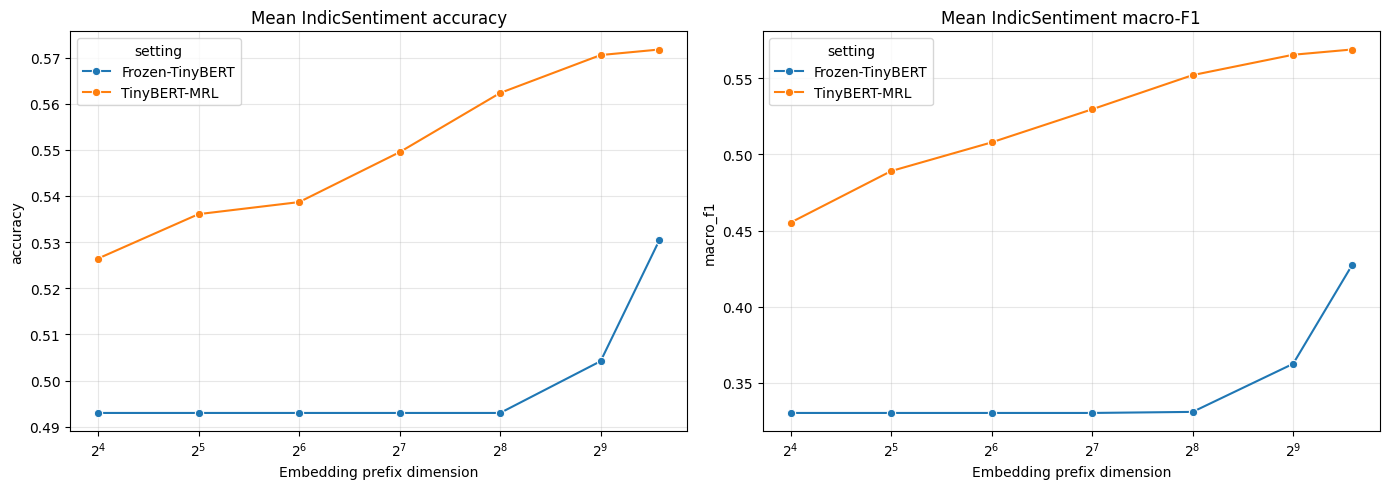

Best mean accuracy by setting:


,setting,dimension,accuracy,macro_f1
6,Frozen-TinyBERT,768,0.530461,0.427141
13,TinyBERT-MRL,768,0.571743,0.568849


All artifacts are in: /kaggle/working/tinybert_indic_mrl_results


In [24]:
fine_tuned_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
model.load_state_dict(torch.load(OUTPUT_DIR / f"tinybert_mrl_epoch_{EPOCHS}.pt", map_location="cpu"))
model.to(DEVICE)
mrl_embedding_dir = extract_all("mrl")
mrl_results = evaluate_embeddings(mrl_embedding_dir, "mrl")

# Reloading from the Hub gives a genuinely frozen pre-MRL baseline.
del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
model = AutoModel.from_pretrained(MODEL_NAME)
if len(tokenizer) != model.get_input_embeddings().num_embeddings:
    model.resize_token_embeddings(len(tokenizer))
model.to(DEVICE)
if hasattr(model.config, "use_cache"):
    model.config.use_cache = False
frozen_embedding_dir = extract_all("frozen")
frozen_results = evaluate_embeddings(frozen_embedding_dir, "frozen")

comparison = pd.concat([mrl_results.assign(setting="TinyBERT-MRL"), frozen_results.assign(setting="Frozen-TinyBERT")], ignore_index=True)
comparison.to_csv(OUTPUT_DIR / "comparison_metrics.csv", index=False)
summary = comparison.groupby(["setting", "dimension"])[["accuracy", "macro_f1"]].mean().reset_index()
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=summary, x="dimension", y="accuracy", hue="setting", marker="o", ax=axes[0])
sns.lineplot(data=summary, x="dimension", y="macro_f1", hue="setting", marker="o", ax=axes[1])
axes[0].set_title("Mean IndicSentiment accuracy")
axes[1].set_title("Mean IndicSentiment macro-F1")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Embedding prefix dimension")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mrl_vs_frozen.png", dpi=160)
plt.show()

best = summary.loc[summary.groupby("setting")["accuracy"].idxmax()]
print("Best mean accuracy by setting:")
display(best[["setting", "dimension", "accuracy", "macro_f1"]])
print(f"All artifacts are in: {OUTPUT_DIR.resolve()}")